# ACL Milestone 1 | Formula 1 Podium Prediction — LabStyle (corrected)

**Prediction goal:** after qualifying and before a Grand Prix starts, estimate whether each driver **entered for that race** will finish on the podium (official `positionOrder` 1, 2 or 3).

**Unit of analysis:** one record per `(raceId, driverId)`. Original shared-drive records are resolved by a documented, reproducible rule.

**Strict cutoff:** only starting-grid, qualifying, and *earlier* race history can be model inputs. Current-race `status`, `laps`, `positionOrder`, and `points` can build the historical outcome and retrospective analysis, but **never decide which entries go into training** or become current-race input features.

**Run All:** attach the **original `archive.zip`** (or a folder containing all 14 CSVs) as a Kaggle input. The loader searches Kaggle and local paths automatically. TensorFlow, SHAP and LIME are used for the neural networks and explainability.

**TA clarification:** The primary model uses all eligible 1950–2019 training races. Shorter historical training windows are explored as diagnostic backtests only; they do not replace the full-history baseline. 2020–2021 is the model-selection period; 2022–2024 is the untouched final test period.

**LabStyle choice:** each section uses straightforward Pandas and scikit-learn code, with readable variable names and ordinary loops, resembling the ACL labs. Sections include EDA, key audits, the three data-engineering questions, chronological feature engineering, four model families/variants, experiments, explainability, and inference.


## 1. Set up the environment and load the data

In [55]:
import os
import io
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, average_precision_score

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
np.random.seed(42)


In [56]:
# Kaggle usually includes TensorFlow and SHAP. LIME sometimes needs installing.
# If a package is missing, enable internet in Kaggle Notebook settings.
import importlib.util
import subprocess
import sys

for package_name in ['tensorflow', 'shap', 'lime']:
    if importlib.util.find_spec(package_name) is None:
        print('Installing missing package:', package_name)
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', package_name])

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
import shap
import lime.lime_tabular

# Fixing the random seed helps reproduce neural-network results.
tf.keras.utils.set_random_seed(42)
try:
    tf.config.experimental.enable_op_determinism()
except Exception as error:
    print('Deterministic TensorFlow operations not available:', error)


In [57]:
# We accept either archive.zip OR an extracted folder containing all 14 CSVs.
# Search the notebook folder, /mnt/data, and Kaggle input folders.
required_tables = [
    'circuits', 'constructors', 'constructor_results', 'constructor_standings',
    'drivers', 'driver_standings', 'races', 'results', 'qualifying',
    'lap_times', 'pit_stops', 'sprint_results', 'seasons', 'status'
]

search_folders = [os.getcwd(), '/mnt/data', '/kaggle/input']
zip_path = None
csv_folder = None

for search_folder in search_folders:
    if not os.path.isdir(search_folder):
        continue

    for current_folder, subfolders, filenames in os.walk(search_folder):
        if 'archive.zip' in filenames:
            candidate = os.path.join(current_folder, 'archive.zip')
            with zipfile.ZipFile(candidate) as archive:
                filenames_in_zip = archive.namelist()
                all_csvs_present = True
                for table_name in required_tables:
                    if table_name + '.csv' not in filenames_in_zip:
                        all_csvs_present = False
                if all_csvs_present:
                    zip_path = candidate
                    break

        all_csvs_present = True
        for table_name in required_tables:
            if table_name + '.csv' not in filenames:
                all_csvs_present = False
        if all_csvs_present:
            csv_folder = current_folder
            break

    if zip_path is not None or csv_folder is not None:
        break

raw = {}  # Keep the original tables unchanged. The cleaning cells make copies.
if zip_path is not None:
    print('Reading ZIP:', zip_path)
    with zipfile.ZipFile(zip_path) as archive:
        for table_name in required_tables:
            filename = table_name + '.csv'
            file_contents = archive.read(filename)
            raw[table_name] = pd.read_csv(io.BytesIO(file_contents), low_memory=False)
elif csv_folder is not None:
    print('Reading CSV folder:', csv_folder)
    for table_name in required_tables:
        filename = os.path.join(csv_folder, table_name + '.csv')
        raw[table_name] = pd.read_csv(filename, low_memory=False)
else:
    raise FileNotFoundError('Attach archive.zip or all 14 original CSVs in Kaggle Input.')

for table_name, table in raw.items():
    print(table_name, 'has', len(table), 'rows and', len(table.columns), 'columns')


Reading CSV folder: /kaggle/input/datasets/yousefsameh04/f1-improted-data/f1_project
circuits has 77 rows and 9 columns
constructors has 212 rows and 5 columns
constructor_results has 12625 rows and 5 columns
constructor_standings has 13391 rows and 7 columns
drivers has 861 rows and 9 columns
driver_standings has 34863 rows and 7 columns
races has 1125 rows and 18 columns
results has 26759 rows and 18 columns
qualifying has 10494 rows and 9 columns
lap_times has 589081 rows and 6 columns
pit_stops has 11371 rows and 7 columns
sprint_results has 360 rows and 16 columns
seasons has 75 rows and 2 columns
status has 139 rows and 2 columns


## 2. EDA before cleaning
First we inspect the data, as in Lab 1: structure, summary statistics, missing values and duplicates.

In [58]:
raw['results'].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26759 entries, 0 to 26758
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   resultId         26759 non-null  int64  
 1   raceId           26759 non-null  int64  
 2   driverId         26759 non-null  int64  
 3   constructorId    26759 non-null  int64  
 4   number           26759 non-null  object 
 5   grid             26759 non-null  int64  
 6   position         26759 non-null  object 
 7   positionText     26759 non-null  object 
 8   positionOrder    26759 non-null  int64  
 9   points           26759 non-null  float64
 10  laps             26759 non-null  int64  
 11  time             26759 non-null  object 
 12  milliseconds     26759 non-null  object 
 13  fastestLap       26759 non-null  object 
 14  rank             26759 non-null  object 
 15  fastestLapTime   26759 non-null  object 
 16  fastestLapSpeed  26759 non-null  object 
 17  statusId    

In [59]:
raw['results'].describe()

,resultId,raceId,driverId,constructorId,grid,positionOrder,points,laps,statusId
count,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000,26759.000000
mean,13380.977391,551.687283,278.673530,50.180537,11.134796,12.794051,1.987632,46.301768,17.224971
std,7726.134642,313.265036,282.703039,61.551498,7.202860,7.665951,4.351209,29.496557,26.026104
min,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000
25%,6690.500000,300.000000,57.000000,6.000000,5.000000,6.000000,0.000000,23.000000,1.000000
50%,13380.000000,531.000000,172.000000,25.000000,11.000000,12.000000,0.000000,53.000000,10.000000
75%,20069.500000,811.000000,399.500000,63.000000,17.000000,18.000000,2.000000,66.000000,14.000000
max,26764.000000,1144.000000,862.000000,215.000000,34.000000,39.000000,50.000000,200.000000,141.000000


In [60]:
raw['results'].head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1


**Missing values are hidden.** `isnull().sum()` reports almost nothing, but the CSVs use the text `\N` to mean "missing". This kind of placeholder is called a **sentinel**. Because of it, numeric columns like `grid`, `position` and `milliseconds` were read as text (`object`). We count the `\N` cells in every table.

isnull() on results finds: 0 missing cells
results                  122887
constructor_results       12608
qualifying                11600
races                     11349
drivers                    1559
sprint_results               73
driver_standings              0
constructor_standings         0
circuits                      0
constructors                  0
lap_times                     0
pit_stops                     0
seasons                       0
status                        0
dtype: int64


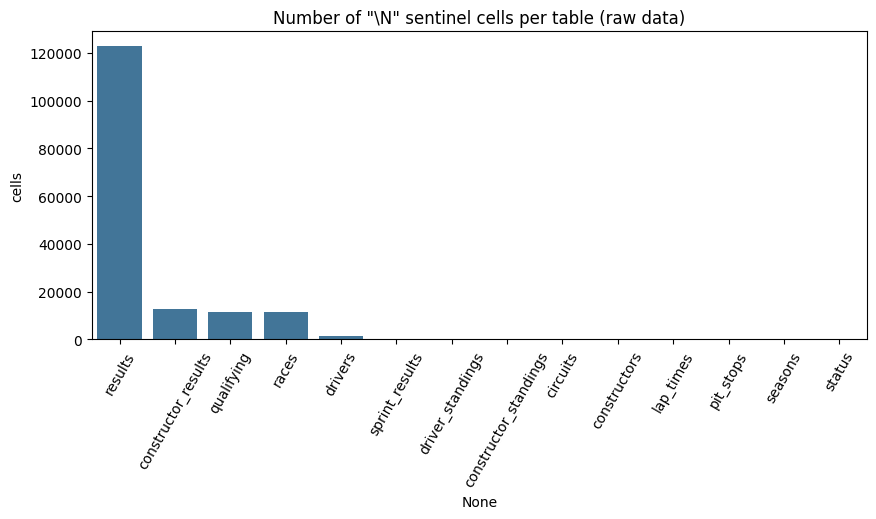

In [61]:
print('isnull() on results finds:', raw['results'].isnull().sum().sum(), 'missing cells')

sentinel_counts = {}
for name, df in raw.items():
    sentinel_counts[name] = int((df == '\\N').sum().sum())
sentinel_counts = pd.Series(sentinel_counts).sort_values(ascending=False)
print(sentinel_counts)

plt.figure(figsize=(10, 4))
sns.barplot(x=sentinel_counts.index, y=sentinel_counts.values, color='#3478a6')
plt.xticks(rotation=60)
plt.title('Number of "\\N" sentinel cells per table (raw data)')
plt.ylabel('cells')
plt.show()

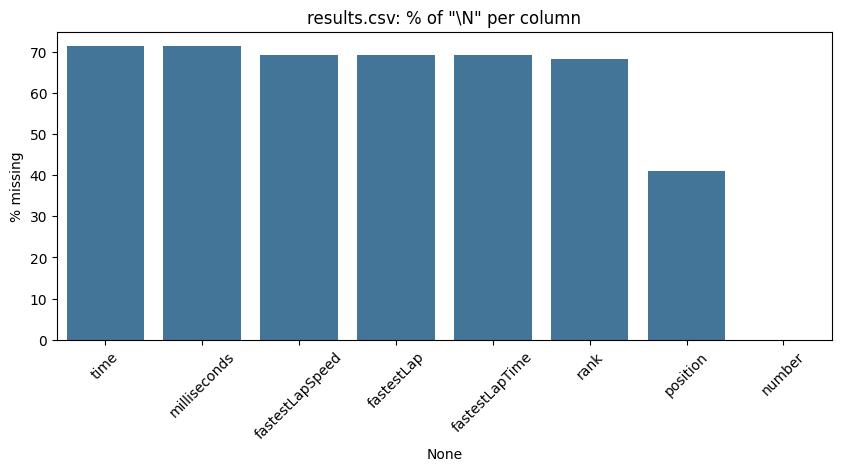

In [62]:
missing_results = (raw['results'] == '\\N').mean().sort_values(ascending=False) * 100
missing_results = missing_results[missing_results > 0]

plt.figure(figsize=(10, 4))
sns.barplot(x=missing_results.index, y=missing_results.values, color='#3478a6')
plt.xticks(rotation=45)
plt.title('results.csv: % of "\\N" per column')
plt.ylabel('% missing')
plt.show()

**Duplicates and era effects.** The modeling table needs exactly one row per `(raceId, driverId)`, so we check for duplicate pairs. We also check how the size of the grid and the amount of qualifying data changed over time.

Duplicate (raceId, driverId) rows in results: 91


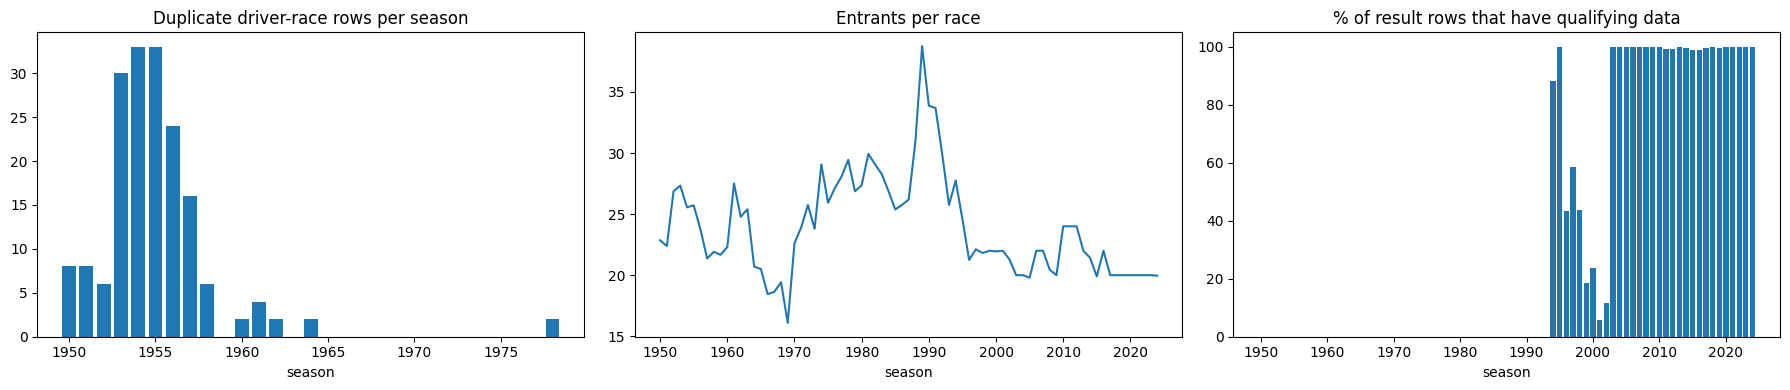

year
1993      0.0
1994     88.0
1995    100.0
1996     44.0
1997     59.0
1998     44.0
1999     18.0
2000     24.0
2001      6.0
2002     12.0
2003    100.0
2004    100.0
Name: driverId, dtype: float64


In [63]:
dup_pairs = raw['results'].duplicated(['raceId', 'driverId']).sum()
print('Duplicate (raceId, driverId) rows in results:', dup_pairs)

res_year = raw['results'].merge(raw['races'][['raceId', 'year']], on='raceId')
qual_year = raw['qualifying'].merge(raw['races'][['raceId', 'year']], on='raceId')

dups_by_year = res_year[res_year.duplicated(['raceId', 'driverId'], keep=False)]['year'].value_counts().sort_index()
entrants = res_year.groupby('year')['driverId'].count() / res_year.groupby('year')['raceId'].nunique()
qual_coverage = (qual_year.groupby('year')['driverId'].count() / res_year.groupby('year')['driverId'].count()).fillna(0) * 100

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].bar(dups_by_year.index, dups_by_year.values)
axes[0].set_title('Duplicate driver-race rows per season')
axes[1].plot(entrants.index, entrants.values)
axes[1].set_title('Entrants per race')
axes[2].bar(qual_coverage.index, qual_coverage.values)
axes[2].set_title('% of result rows that have qualifying data')
for ax in axes:
    ax.set_xlabel('season')
plt.tight_layout()
plt.show()
print(qual_coverage.loc[1993:2004].round(0))

**What the raw EDA shows:**
- **Duplicates:** almost all duplicate driver-race rows are from the 1950s. Back then drivers could share or take over a teammate's car mid-race.
- **Field size:** old races had 30+ entrants, including cars that never even qualified. Modern races have about 20.
- **Qualifying coverage drift:** qualifying data only starts in **1994** and is incomplete until **2003**. Before that, qualifying-based features will be missing, and we have to deal with this.

## 3. Cleaning

### 3.1 Replace sentinels and fix data types
Steps:
- Every `\N` becomes `NaN`.
- Numeric text columns become numbers, and dates become datetime.
- Lap-time strings like `"1:27.452"` become seconds (`87.452`) so they can be compared.
- Leading, trailing, and repeated internal whitespace are normalized in driver nationality and circuit country. For example, there is a nationality `"Argentinian "` with a trailing space.

In [64]:
clean = {}
for name, df in raw.items():
    clean[name] = df.copy().replace('\\N', np.nan)


def time_to_seconds(t):
    """'1:27.452' -> 87.452 seconds, '27.452' -> 27.452, missing -> NaN"""
    if pd.isnull(t):
        return np.nan
    parts = str(t).split(':')
    seconds = 0.0
    for p in parts:
        seconds = seconds * 60 + float(p)
    return seconds


for col in ['number', 'grid', 'position', 'positionOrder', 'points', 'laps', 'milliseconds',
            'fastestLap', 'rank', 'fastestLapSpeed']:
    clean['results'][col] = pd.to_numeric(clean['results'][col])
clean['qualifying']['position'] = pd.to_numeric(clean['qualifying']['position'])
for t in ['driver_standings', 'constructor_standings']:
    for col in ['points', 'position', 'wins']:
        clean[t][col] = pd.to_numeric(clean[t][col])

clean['races']['date'] = pd.to_datetime(clean['races']['date'])
clean['drivers']['dob'] = pd.to_datetime(clean['drivers']['dob'])

for q in ['q1', 'q2', 'q3']:
    clean['qualifying'][q + '_seconds'] = clean['qualifying'][q].apply(time_to_seconds)
clean['results']['fastestLap_seconds'] = clean['results']['fastestLapTime'].apply(time_to_seconds)

# Whitespace must be normalized in BOTH fields used for home-country matching.
# This removes leading/trailing whitespace and collapses multiple inner spaces.
clean['drivers']['nationality'] = clean['drivers']['nationality'].str.strip()
clean['drivers']['nationality'] = clean['drivers']['nationality'].str.replace(r'\s+', ' ', regex=True)
clean['circuits']['country'] = clean['circuits']['country'].str.strip()
clean['circuits']['country'] = clean['circuits']['country'].str.replace(r'\s+', ' ', regex=True)

print('Sentinels left after cleaning:', sum(int((df == '\\N').sum().sum()) for df in clean.values()))
print(clean['results'][['grid', 'position', 'milliseconds']].dtypes)
print('Lap time example:', raw['qualifying']['q1'].iloc[0], '->', clean['qualifying']['q1_seconds'].iloc[0], 'seconds')

Sentinels left after cleaning: 0
grid              int64
position        float64
milliseconds    float64
dtype: object
Lap time example: 1:26.572 -> 86.572 seconds


### 3.2 Keep seasons 1950–2024 only
The milestone uses 1950–2024. If the dataset copy contains newer seasons, we drop them from every table.

In [65]:
clean['races'] = clean['races'][clean['races']['year'] <= 2024]
valid_races = clean['races']['raceId']
for name in ['results', 'qualifying', 'driver_standings', 'constructor_standings',
             'constructor_results', 'sprint_results', 'pit_stops', 'lap_times']:
    clean[name] = clean[name][clean[name]['raceId'].isin(valid_races)]
clean['seasons'] = clean['seasons'][clean['seasons']['year'] <= 2024]
print('Seasons:', clean['races']['year'].min(), '-', clean['races']['year'].max())
print('Result rows:', len(clean['results']))

Seasons: 1950 - 2024
Result rows: 26759


### 3.3 Primary keys and foreign keys
- **Primary key:** the column(s) that uniquely identify a row. It must be unique and never null.
- **Foreign key:** an id that points to another table. Every value must exist in that table. For example, every `results.driverId` must exist in `drivers`.

In [66]:
# Audit keys: do not silently remove bad primary-key rows.
# Fixes need an explicit rule rather than an unnoticed drop_duplicates.
primary_keys = {
    'circuits': ['circuitId'], 'constructors': ['constructorId'],
    'drivers': ['driverId'], 'races': ['raceId'], 'status': ['statusId'],
    'seasons': ['year'], 'results': ['resultId'], 'qualifying': ['qualifyId'],
    'driver_standings': ['driverStandingsId'],
    'constructor_standings': ['constructorStandingsId'],
    'constructor_results': ['constructorResultsId'], 'sprint_results': ['resultId'],
    'pit_stops': ['raceId', 'driverId', 'stop'],
    'lap_times': ['raceId', 'driverId', 'lap']
}

pk_rows = []
for table_name, key_columns in primary_keys.items():
    table = clean[table_name]
    missing_keys = int(table[key_columns].isnull().any(axis=1).sum())
    duplicate_keys = int(table.duplicated(key_columns).sum())
    pk_rows.append({'table': table_name, 'key': str(key_columns),
                    'null keys': missing_keys, 'duplicate keys': duplicate_keys})
    if missing_keys > 0 or duplicate_keys > 0:
        raise ValueError('Invalid primary key in ' + table_name)

pk_audit = pd.DataFrame(pk_rows)
display(pk_audit)


,table,key,null keys,duplicate keys
0,circuits,['circuitId'],0,0
1,constructors,['constructorId'],0,0
2,drivers,['driverId'],0,0
3,races,['raceId'],0,0
4,status,['statusId'],0,0
5,seasons,['year'],0,0
6,results,['resultId'],0,0
7,qualifying,['qualifyId'],0,0
8,driver_standings,['driverStandingsId'],0,0
9,constructor_standings,['constructorStandingsId'],0,0


In [67]:
foreign_keys = [
    ('results', 'raceId', 'races'), ('results', 'driverId', 'drivers'),
    ('results', 'constructorId', 'constructors'), ('results', 'statusId', 'status'),
    ('qualifying', 'raceId', 'races'), ('qualifying', 'driverId', 'drivers'),
    ('driver_standings', 'raceId', 'races'), ('driver_standings', 'driverId', 'drivers'),
    ('constructor_standings', 'raceId', 'races'),
    ('constructor_standings', 'constructorId', 'constructors'),
    ('races', 'circuitId', 'circuits'), ('pit_stops', 'raceId', 'races'),
    ('lap_times', 'raceId', 'races')
]
foreign_keys += [
    ('qualifying', 'constructorId', 'constructors'),

    ('constructor_results', 'raceId', 'races'),
    ('constructor_results', 'constructorId', 'constructors'),

    ('pit_stops', 'driverId', 'drivers'),
    ('lap_times', 'driverId', 'drivers'),

    ('sprint_results', 'raceId', 'races'),
    ('sprint_results', 'driverId', 'drivers'),
    ('sprint_results', 'constructorId', 'constructors'),
    ('sprint_results', 'statusId', 'status'),

    ('races', 'year', 'seasons')
]

fk_rows = []
for child_table, column, parent_table in foreign_keys:
    orphan_rows = (~clean[child_table][column].isin(clean[parent_table][column])).sum()
    fk_rows.append({'child': child_table + '.' + column,
                    'parent': parent_table, 'orphan rows': int(orphan_rows)})

fk_audit = pd.DataFrame(fk_rows)
display(fk_audit)
if fk_audit['orphan rows'].sum() != 0:
    raise ValueError('At least one foreign key does not match its parent table')


,child,parent,orphan rows
0,results.raceId,races,0
1,results.driverId,drivers,0
2,results.constructorId,constructors,0
3,results.statusId,status,0
4,qualifying.raceId,races,0
5,qualifying.driverId,drivers,0
6,driver_standings.raceId,races,0
7,driver_standings.driverId,drivers,0
8,constructor_standings.raceId,races,0
9,constructor_standings.constructorId,constructors,0


**What these checks prove:** Every audited primary key is non-null and unique, and every audited foreign key exists in its parent table. The checks stop if that is untrue; they do **not** quietly remove source rows.

`raceId` is not chronological. The chronological features below sort by the actual race calendar, never by numeric `raceId` alone.


In [68]:
clean['races'].sort_values('raceId')[['raceId', 'year', 'round', 'name']].iloc[15:20]

,raceId,year,round,name
15,16,2009,16,Brazilian Grand Prix
16,17,2009,17,Abu Dhabi Grand Prix
17,18,2008,1,Australian Grand Prix
18,19,2008,2,Malaysian Grand Prix
19,20,2008,3,Bahrain Grand Prix


### 3.4 Define the correct pre-race prediction population

**Important correction:** We retain every driver–race entry in `results.csv`, including the historical Indianapolis 500 championship races and drivers who later did not start. The milestone defines an *entered driver–race* prediction. Removing a row because its **post-race status says "Withdrew"** would use future information to decide who enters the model—and can exclude drivers who completed laps.

We can use actual `status` and `laps` later for retrospective mechanical-retirement analysis, but we **never filter the prediction table by those outcomes**.

A `grid=0` record can mean different things historically; we preserve it and create a separate `pit_lane_start` **proxy flag** instead of making a post-race decision about it. This limitation is disclosed in the final section.


In [69]:
# Combine results with race schedule and status descriptions.
# Status is attached for retrospective analysis, NOT used to exclude model rows.
results = clean['results'].merge(
    clean['races'][['raceId', 'year', 'round', 'date', 'circuitId', 'name']],
    on='raceId', how='inner', validate='many_to_one'
)
results = results.merge(clean['status'], on='statusId', how='left', validate='many_to_one')

print('Result records before shared-drive deduplication:', len(results))
print('Indianapolis 500 rows retained:', int((results['name'] == 'Indianapolis 500').sum()))
print('Rows with grid 0 retained:', int((results['grid'] == 0).sum()))
print('Retained entries with Withdrew status but completed laps:',
      len(results[(results['status'] == 'Withdrew') & (results['laps'] > 0)]))


Result records before shared-drive deduplication: 26759
Indianapolis 500 rows retained: 405
Rows with grid 0 retained: 1638
Retained entries with Withdrew status but completed laps: 23


### 3.5 Make `(raceId, driverId)` unique

Early shared drives sometimes appear more than once for the same driver and race. This notebook **keeps the row with the smallest `resultId`** for each duplicate driver–race pair, as an explicit, reproducible source-record rule. We do **not** claim that the smallest `resultId` always identifies the driver's original car—`resultId` is only a database key, not a documented car-ownership flag.

The target is based on the retained record's `positionOrder`. Shared-drive credit rules can make a handful of early podium labels ambiguous. We compare against an alternative best-finish rule as a sensitivity check, without using that target-optimizing rule in our main pipeline.


In [70]:
duplicates = results[results.duplicated(['raceId', 'driverId'], keep=False)]
print('Duplicated driver-race pairs:', duplicates.groupby(['raceId', 'driverId']).ngroups)
example = duplicates[(duplicates['year'] == 1957) & (duplicates['name'] == 'British Grand Prix')]
display(example[['year', 'name', 'driverId', 'number', 'grid',
                 'positionOrder', 'laps', 'status', 'resultId']])

# Make two copies so we can compare alternative, documented deduplication rules.
keep_first_id = results.sort_values('resultId').drop_duplicates(['raceId', 'driverId'])
keep_best_finish = results.sort_values('positionOrder').drop_duplicates(['raceId', 'driverId'])
print('Podiums with first resultId:', int(keep_first_id['positionOrder'].between(1, 3).sum()))
print('Podiums with best finish:', int(keep_best_finish['positionOrder'].between(1, 3).sum()))

results = keep_first_id.copy()
assert not results.duplicated(['raceId', 'driverId']).any()
print('Model population after deduplication:', len(results))


Duplicated driver-race pairs: 85


,year,name,driverId,number,grid,positionOrder,laps,status,resultId
18805,1957,British Grand Prix,479,20.0,3,1,90,Finished,18806
18815,1957,British Grand Prix,581,12.0,8,11,53,Water leak,18816
18816,1957,British Grand Prix,475,18.0,1,12,51,Engine,18817
20288,1957,British Grand Prix,475,20.0,3,1,90,Finished,20291
20289,1957,British Grand Prix,581,16.0,9,4,88,+2 Laps,20292
20290,1957,British Grand Prix,479,18.0,1,12,51,Engine,20293


Podiums with first resultId: 3379
Podiums with best finish: 3395
Model population after deduplication: 26668


### 3.6 Build the cleaned analytical table
We join circuits (name and country), drivers (name and nationality), constructors (team name) and the qualifying position, then add the target.

In [71]:
circuits = clean['circuits'][['circuitId', 'name', 'country']].copy()
circuits = circuits.rename(columns={'name': 'circuit_name'})
circuits['country'] = circuits['country'].replace({'United States': 'USA'})

drivers = clean['drivers'][['driverId', 'driverRef', 'forename', 'surname', 'nationality']].copy()
drivers['driver_name'] = drivers['forename'] + ' ' + drivers['surname']

constructors = clean['constructors'][['constructorId', 'name']].copy()
constructors = constructors.rename(columns={'name': 'constructor_name'})

qualifying = clean['qualifying'][['raceId', 'driverId', 'position', 'q1_seconds']].copy()
qualifying = qualifying.rename(columns={'position': 'quali_position'})
assert not qualifying.duplicated(['raceId', 'driverId']).any()

base = results.rename(columns={'name': 'race_name'}).copy()
base = base.merge(circuits, on='circuitId', how='left', validate='many_to_one')
base = base.merge(drivers[['driverId', 'driverRef', 'driver_name', 'nationality']],
                  on='driverId', how='left', validate='many_to_one')
base = base.merge(constructors, on='constructorId', how='left', validate='many_to_one')
base = base.merge(qualifying, on=['raceId', 'driverId'], how='left', validate='one_to_one')

# The current-race finishing position is used ONLY to build the target label.
base['podium'] = base['positionOrder'].between(1, 3).astype(int)
base = base.sort_values(['date', 'year', 'round', 'raceId', 'driverId']).reset_index(drop=True)
assert not base.duplicated(['raceId', 'driverId']).any()
print('Model population:', base.shape, '| unique driver-races:', len(base))
display(base[['year', 'race_name', 'driver_name', 'constructor_name',
              'grid', 'quali_position', 'positionOrder', 'podium']].tail())


Model population: (26668, 34) | unique driver-races: 26668


,year,race_name,driver_name,constructor_name,grid,quali_position,positionOrder,podium
26663,2024,Abu Dhabi Grand Prix,Guanyu Zhou,Sauber,15,17.0,13,0
26664,2024,Abu Dhabi Grand Prix,Oscar Piastri,McLaren,2,2.0,10,0
26665,2024,Abu Dhabi Grand Prix,Liam Lawson,RB F1 Team,12,12.0,17,0
26666,2024,Abu Dhabi Grand Prix,Franco Colapinto,Williams,20,19.0,19,0
26667,2024,Abu Dhabi Grand Prix,Jack Doohan,Alpine F1 Team,17,20.0,15,0


## 4. EDA after cleaning

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
raw_grid = pd.to_numeric(raw['results']['grid'], errors='coerce')
axes[0].hist(raw_grid.clip(upper=35), bins=36, alpha=0.6, label='raw')
axes[0].hist(base['grid'].clip(upper=35), bins=36, alpha=0.6, label='deduplicated')
axes[0].set_title('Starting grid before vs after deduplication')
axes[0].legend()

raw_with_year = res_year.copy()
raw_with_year['podium'] = pd.to_numeric(raw_with_year['positionOrder'], errors='coerce').between(1, 3)
raw_podium_rate = raw_with_year.groupby('year')['podium'].mean() * 100
clean_podium_rate = base.groupby('year')['podium'].mean() * 100
axes[1].plot(raw_podium_rate.index, raw_podium_rate.values, label='raw')
axes[1].plot(clean_podium_rate.index, clean_podium_rate.values, label='deduplicated')
axes[1].set_title('Historical podium frequency by season (%)')
axes[1].legend()

sns.countplot(x='podium', data=base, ax=axes[2], color='#3478a6')
axes[2].set_title('Target balance: ' + str(round(base['podium'].mean() * 100, 1)) + '% podium')
plt.tight_layout()
plt.show()


In [ ]:
podium_by_grid = base[base['grid'].between(1, 20)].groupby('grid')['podium'].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
sns.barplot(x=podium_by_grid.index.astype(int), y=podium_by_grid.values, ax=axes[0], color='#3478a6')
axes[0].set_title('Podium rate by starting grid position')
axes[0].set_ylabel('podium rate %')
sns.boxplot(x='podium', y='grid', data=base[base['grid'] > 0], ax=axes[1])
axes[1].set_title('Grid position of podium vs non-podium finishers')
plt.tight_layout()
plt.show()

### 4.1 Does the link between starting grid and podium change over time?

**TA clarification:** we must not discard old years just because the rules changed. This figure **uses the full 1950–2024 history** to show how the grid-to-podium association differs across eras. It is descriptive EDA, not a causal claim or a reason to inspect test performance before choosing a model.

We show the number of observations by era as well as podium rate. Qualifying coverage is also reported because qualifying fields are largely missing in early decades. This motivates comparing full-history training to shorter windows **without discarding the old history**.

In [ ]:
# Compare the relationship between starting position and podium across F1 eras.
era_edges = [1949, 1969, 1989, 2002, 2013, 2024]
era_names = ['1950-1969', '1970-1989', '1990-2002', '2003-2013', '2014-2024']

era_data = base.copy()
era_data['historical_era'] = pd.cut(era_data['year'], bins=era_edges, labels=era_names)

era_summary = era_data.groupby('historical_era', observed=True).agg(
    driver_races=('podium', 'size'),
    podium_rate=('podium', 'mean'),
    qualifying_coverage=('quali_position', 'count')
).reset_index()
era_summary['qualifying_coverage'] = era_summary['qualifying_coverage'] / era_summary['driver_races']

# Only actual positive starting grid positions are used in this comparison.
grid_data = era_data[era_data['grid'].between(1, 12)].copy()
era_grid_rates = grid_data.groupby(['historical_era', 'grid'], observed=True).agg(
    podium_rate=('podium', 'mean'),
    starts=('podium', 'size')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
for era_name in era_names:
    selected_rows = era_grid_rates[era_grid_rates['historical_era'] == era_name]
    selected_rows = selected_rows[selected_rows['starts'] >= 10]
    axes[0].plot(selected_rows['grid'], selected_rows['podium_rate'] * 100,
                 marker='o', label=era_name)
axes[0].set_title('Does grid-to-podium association change across F1 eras?')
axes[0].set_xlabel('Starting grid position')
axes[0].set_ylabel('Historical podium rate (%)')
axes[0].legend()

axes[1].bar(era_summary['historical_era'].astype(str),
            era_summary['qualifying_coverage'] * 100)
axes[1].set_title('Qualifying-position coverage differs by era')
axes[1].set_xlabel('Era')
axes[1].set_ylabel('Records with qualifying position (%)')
axes[1].tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.show()

print('Historical era summary:')
display(era_summary.round(3))

**After-cleaning EDA:** We retained entered drivers rather than filtering them by race outcomes, so `grid=0` entries remain. The biggest dataset changes are sentinel typing, season scope, and shared-drive deduplication—not the deletion of non-starters. Use the graph above for the observed percentages instead of assuming a fixed podium rate.

**Predictive evidence:** Starting near the front strongly correlates with finishing on the podium, but this is a historical association, not a guarantee. Most entrants do not podium, so PR-AUC and F1 are more useful than accuracy alone for comparing classifiers.

## 5. Data-engineering questions

### Q1. Which circuits convert a front-row start into a podium, and does this change after 2014?

- **Grid front row:** cars listed at grid position 1 or 2.
- **Qualifying front row:** drivers with qualifying position 1 or 2 (can differ after penalties).
- **Eras:** 1950–2013 versus 2014–2024.
- **Minimum sample:** at least 10 front-row starts in an era for ranked circuits. Rates on very small samples are unstable.


In [ ]:
q1 = base.copy()
q1['era'] = np.where(q1['year'] >= 2014, '2014-2024', '1950-2013')
front = q1[q1['grid'].isin([1, 2])]

print(front.groupby('era')['podium'].agg(['mean', 'count']))

conversion = front.groupby(['era', 'circuit_name'])['podium'].agg(['mean', 'count']).reset_index()
conversion = conversion[conversion['count'] >= 10]

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, era in zip(axes, ['1950-2013', '2014-2024']):
    top = conversion[conversion['era'] == era].sort_values('mean', ascending=False).head(10)
    sns.barplot(x=top['mean'] * 100, y=top['circuit_name'], ax=ax, color='#3478a6')
    ax.set_title(f'Top front-row -> podium circuits, {era}')
    ax.set_xlabel('% of front-row starts that ended on the podium')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

In [ ]:
%pip install -q adjustText

In [ ]:
# Find circuits that have enough data in both eras.
both_eras = conversion.pivot_table(
    index='circuit_name',
    columns='era',
    values='mean'
).dropna()

# Calculate how similar the circuit rankings are.
rank_corr = both_eras['1950-2013'].corr(
    both_eras['2014-2024'],
    method='spearman'
)

print('Circuits in both eras:', len(both_eras))
print('Spearman rank correlation:', round(rank_corr, 2))


# Prepare the data for plotting.
plot_data = both_eras.copy()

plot_data['Before 2014'] = plot_data['1950-2013'] * 100
plot_data['After 2014'] = plot_data['2014-2024'] * 100

plot_data['Change'] = (
    plot_data['After 2014'] - plot_data['Before 2014']
)

# Sort circuits by how much their conversion rate changed.
plot_data = plot_data.sort_values('Change')


# Create the figure.
fig, ax = plt.subplots(figsize=(13, 10))

positions = range(len(plot_data))

# Connect the two era values for each circuit.
for position, (circuit, row) in enumerate(plot_data.iterrows()):

    ax.plot(
        [row['Before 2014'], row['After 2014']],
        [position, position],
        color='lightgray',
        linewidth=2
    )

# Plot the conversion rates for both eras.
ax.scatter(
    plot_data['Before 2014'],
    positions,
    color='steelblue',
    s=90,
    label='1950–2013',
    zorder=3
)

ax.scatter(
    plot_data['After 2014'],
    positions,
    color='darkorange',
    s=90,
    label='2014–2024',
    zorder=3
)

# Put circuit names on separate lines.
ax.set_yticks(list(positions))
ax.set_yticklabels(plot_data.index, fontsize=10)

ax.set_xlim(0, 100)

In [ ]:
# Qualifying front row vs grid front row (2003-2024, where qualifying data is complete)
qq = q1[(q1['year'] >= 2003) & q1['quali_position'].notna()].copy()
qq['qualified_front_row'] = qq['quali_position'] <= 2
qq['started_front_row'] = qq['grid'].isin([1, 2])
qual_vs_grid = qq.pivot_table(index='qualified_front_row', columns='started_front_row', values='podium', aggfunc='mean')

sns.heatmap(qual_vs_grid, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Podium rate: qualified on front row vs started on front row')
plt.show()
print(qq.pivot_table(index='qualified_front_row', columns='started_front_row', values='podium', aggfunc='count'))

**Q1 interpretation (read the tables and figures above):** The front-row-to-podium rate is calculated as podiums divided by front-row starts, separately by circuit and era. The plotted ranking uses at least 10 relevant starts. The same-circuit comparison tests whether rankings remain similar between eras. Qualifying position is separately compared with the actual grid, since penalties can make the two different.

**Caution:** Era differences can reflect vehicle reliability, competitive balance, and changing rules; they cannot be attributed to the circuit alone. Rankings with small sample sizes should not be treated as precise causal effects.

### Q2. Is there a home-race podium advantage after accounting for grid position?

The driver nationality is mapped to a country, which is matched to `circuits.country`. **For this descriptive question**, we consider actual race starters (a positive grid or completed laps) and exclude unrecognized nationality codes. This retrospective restriction is **not applied to the pre-race model population**. We compare podium rates within starting-grid bands, then fit an adjusted logistic regression with grid-band and decade controls.


In [ ]:
nationality_to_country = {
    'British': 'UK', 'American': 'USA', 'American-Italian': 'USA', 'Dutch': 'Netherlands', 'German': 'Germany',
    'East German': 'Germany', 'Italian': 'Italy', 'French': 'France', 'Spanish': 'Spain', 'Brazilian': 'Brazil',
    'Australian': 'Australia', 'Canadian': 'Canada', 'Austrian': 'Austria', 'Belgian': 'Belgium',
    'Finnish': 'Finland', 'Swedish': 'Sweden', 'Swiss': 'Switzerland', 'Portuguese': 'Portugal',
    'Argentine': 'Argentina', 'Argentinian': 'Argentina', 'Argentine-Italian': 'Argentina',
    'South African': 'South Africa', 'Japanese': 'Japan', 'Mexican': 'Mexico', 'Venezuelan': 'Venezuela',
    'Danish': 'Denmark', 'Russian': 'Russia', 'Polish': 'Poland', 'Indian': 'India', 'Malaysian': 'Malaysia',
    'Thai': 'Thailand', 'Chinese': 'China', 'Irish': 'Ireland', 'New Zealander': 'New Zealand',
    'Monegasque': 'Monaco', 'Hungarian': 'Hungary', 'Czech': 'Czech Republic', 'Colombian': 'Colombia',
    'Chilean': 'Chile', 'Uruguayan': 'Uruguay', 'Indonesian': 'Indonesia', 'Rhodesian': 'Rhodesia',
    'Liechtensteiner': 'Liechtenstein'}

# A retrospective home-race comparison should use actual starters, not DNS entries.
# Completed laps are allowed HERE because this is analysis of history, not a model feature.
q2 = base[(base['grid'] > 0) | (base['laps'] > 0)].copy()
q2['driver_country'] = q2['nationality'].map(nationality_to_country)
print('Excluded rows with unknown driver country:', int(q2['driver_country'].isna().sum()))
q2 = q2[q2['driver_country'].notna() & q2['country'].notna()].copy()
q2['home'] = (q2['driver_country'] == q2['country']).astype(int)
print('Nationalities without a mapping:', q2[q2['driver_country'].isnull()]['nationality'].unique())
print('Home starts:', q2['home'].sum(), 'of', len(q2))
print(q2.groupby('home')['podium'].mean())

q2['grid_band'] = pd.cut(q2['grid'].replace(0, 30), bins=[0, 1, 3, 6, 10, 100],
                         labels=['P1', 'P2-3', 'P4-6', 'P7-10', 'P11+'])
q2['decade'] = (q2['year'] // 10) * 10

home_pivot = q2.pivot_table(index='grid_band', columns='home', values='podium', aggfunc='mean')
home_pivot.columns = ['away', 'home']

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.heatmap(home_pivot, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[0])
axes[0].set_title('Podium rate by grid band: away vs home')
sns.barplot(data=q2, x='grid_band', y='podium', hue='home', ax=axes[1])
axes[1].set_title('Same comparison with 95% error bars')
plt.tight_layout()
plt.show()


In [ ]:
def home_odds_ratio(data):
    X = pd.get_dummies(data[['grid_band', 'decade']].astype(str), drop_first=True)
    X['home'] = data['home'].values
    model = LogisticRegression(max_iter=1000)
    model.fit(X, data['podium'])
    return np.exp(model.coef_[0][list(X.columns).index('home')])


odds_ratio = home_odds_ratio(q2)

# Bootstrap: refit on 200 resampled copies of the data to get a 95% interval
boot = []
for b in range(200):
    sample = q2.sample(len(q2), replace=True, random_state=b)
    boot.append(home_odds_ratio(sample))
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])
print(f'Home odds ratio (controlling for grid band and decade): {odds_ratio:.3f}  '
      f'95% bootstrap interval: [{ci_low:.3f}, {ci_high:.3f}]')

plt.figure(figsize=(7, 3))
plt.hist(boot, bins=30)
plt.axvline(1, color='k', ls='--', label='no effect (OR = 1)')
plt.axvline(odds_ratio, color='r', label='estimate')
plt.title('Bootstrap distribution of the home odds ratio')
plt.legend()
plt.show()

**Q2 interpretation:** The heatmap shows the podium rate for home and away starts **within comparable grid bands**. The next cell reports an odds ratio with a 95% bootstrap confidence interval, adjusted for grid band and decade. An interval containing 1 does **not** provide convincing evidence of an adjusted home advantage or disadvantage. The observed association is not causal: team competitiveness, driver skill, circuit familiarity and many other factors can confound it.

### Q3. Which constructors have the highest mechanical-retirement rates, 2014–2021 vs 2022–2024?

A **mechanical retirement** is an actual race starter whose recorded exit status points to a car component failure. We exclude crash, driver and regulation statuses; ambiguous labels can cause classification error. For this retrospective question, an actual start means a positive grid or at least one completed lap. Use at least 30 starts per constructor in an era for the plotted rankings.


In [ ]:
mechanical_statuses = ['Engine', 'Gearbox', 'Power Unit', 'Brakes', 'Suspension', 'Hydraulics', 'Electrical',
                       'Power loss', 'Oil leak', 'Overheating', 'Mechanical', 'Water pressure', 'Turbo', 'ERS',
                       'Exhaust', 'Battery', 'Fuel pressure', 'Water leak', 'Electronics', 'Transmission',
                       'Radiator', 'Oil pressure', 'Technical', 'Clutch', 'Throttle', 'Vibrations', 'Driveshaft',
                       'Steering', 'Fuel leak', 'Drivetrain', 'Fuel system', 'Brake duct', 'Spark plugs',
                       'Cooling system', 'Water pump', 'Fuel pump', 'Differential']

# Retrospective actual-start denominator: grid positive OR at least one completed lap.
q3 = base[(base['year'] >= 2014) & ((base['grid'] > 0) | (base['laps'] > 0))].copy()
q3['era'] = np.where(q3['year'] <= 2021, '2014-2021', '2022-2024')
q3['mechanical'] = q3['status'].isin(mechanical_statuses).astype(int)

print('Statuses in 2014-2024 that we did NOT count as mechanical:')
print(q3[q3['mechanical'] == 0]['status'].value_counts().head(15))
print('\nOverall mechanical-retirement rate:')
print(q3.groupby('era')['mechanical'].mean())

team_rates = q3.groupby(['era', 'constructor_name'])['mechanical'].agg(['mean', 'sum', 'count']).reset_index()
team_rates = team_rates[team_rates['count'] >= 30]

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, era in zip(axes, ['2014-2021', '2022-2024']):
    t = team_rates[team_rates['era'] == era].sort_values('mean', ascending=False)
    sns.barplot(x=t['mean'] * 100, y=t['constructor_name'], ax=ax, color='#3478a6')
    ax.set_title(f'Mechanical retirements per start, {era}')
    ax.set_xlabel('% of starts')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

for era in ['2014-2021', '2022-2024']:
    print(f'\nTop 5 {era}:')
    print(team_rates[team_rates['era'] == era].sort_values('mean', ascending=False).head(5).round(3).to_string(index=False))


**Q3 interpretation:** The code reports the actual mechanical-retirement rates for both periods and ranks the constructors with at least 30 starts. The figures above—not a hard-coded list—are the authoritative rankings for the attached CSV version.

**Limitations:** 2022–2024 covers only three seasons; some component failures might be coded with vague statuses; team-name changes can split otherwise continuous organizations into separate constructor IDs. These outcomes are used only in retrospective analysis, **never as current-race model features**.


## 6. Feature engineering (leakage-safe)
Every feature must be known **before the race starts**. The rule for "form" features: use `shift(1)` so a row only sees **previous** races, never the current one.

| Group | Features | Why it is allowed at the cutoff |
|---|---|---|
| grid | `grid_pos` (pit lane = back of grid), `pit_lane_start` | The grid is fixed before the start |
| qualifying | `quali_position`, `quali_gap_pct` (Q1 time vs fastest Q1, in %) | Qualifying happens before the race |
| driver_form | podium rate and average finish over the last 5 races, number of earlier starts | `shift(1)`: previous races only |
| constructor_form | team podiums per race and best finish over its last 5 races | Grouped to one row per team per race **first**, then shifted, so a teammate's result in the *same* race never leaks |
| standings | driver and team championship rank and share of the leader's points | Taken from the standings after the **previous round of the same season**. Round 1 means 0 points |

Two choices make the features comparable across eras:
- **Points systems changed** (a win was worth 9–10 points before 2010 and 25 after), so we use the **share of the leader's points**, not raw points.
- **Field sizes changed**, so finishing position is used as a percentage of the field.

In [ ]:
# Create an actual chronological race index (raceId numbers are not chronological).
race_calendar = clean['races'].sort_values(['date', 'year', 'round', 'raceId']).copy()
race_calendar['race_order'] = range(len(race_calendar))
df = base.merge(race_calendar[['raceId', 'race_order']], on='raceId', how='left')
df = df.sort_values(['race_order', 'driverId']).reset_index(drop=True)

# ---- grid
df['field_size'] = df.groupby('raceId')['driverId'].transform('count')
df['pit_lane_start'] = (df['grid'] == 0).astype(int)  # historical zero-grid indicator
# Assign grid 0 to the back of the field, and keep a separate zero-grid flag.
# Grid 0 is not automatically a confirmed pit-lane start, so treat it as a proxy.
df['grid_pos'] = df['grid'].replace(0, np.nan).fillna(df['field_size'] + 1)

# ---- qualifying
fastest_q1 = df.groupby('raceId')['q1_seconds'].transform('min')
df['quali_gap_pct'] = ((df['q1_seconds'] / fastest_q1 - 1) * 100).clip(0, 15)

# ---- driver form (previous races only)
df['finish_pct'] = (df['positionOrder'] / df['field_size']).clip(upper=1)   # helper: result of THIS race, never a feature
df['drv_podium_rate_last5'] = df.groupby('driverId')['podium'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
df['drv_finish_pct_last5'] = df.groupby('driverId')['finish_pct'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
df['drv_starts_before'] = df.groupby('driverId').cumcount()

# ---- constructor form: first one row per team per race, then shift
team = df.groupby(['constructorId', 'raceId', 'date'], as_index=False).agg(
    team_podiums=('podium', 'sum'), team_best_pct=('finish_pct', 'min')).sort_values('date')
team['cons_podiums_last5'] = team.groupby('constructorId')['team_podiums'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
team['cons_best_pct_last5'] = team.groupby('constructorId')['team_best_pct'].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
df = df.merge(team[['constructorId', 'raceId', 'cons_podiums_last5', 'cons_best_pct_last5']],
              on=['constructorId', 'raceId'], how='left', validate='many_to_one')

# ---- standings BEFORE the race = standings after the previous round of the same season
races_sorted = clean['races'].sort_values(['year', 'round'])[['raceId', 'year', 'round']].copy()
races_sorted['prev_raceId'] = races_sorted.groupby('year')['raceId'].shift(1)
df = df.merge(races_sorted[['raceId', 'prev_raceId']], on='raceId', how='left')

ds = clean['driver_standings'][['raceId', 'driverId', 'points', 'position']].copy()
ds['drv_champ_pts_share'] = ds['points'] / ds.groupby('raceId')['points'].transform('max')
ds = ds.rename(columns={'raceId': 'prev_raceId', 'position': 'drv_champ_rank_before'})
ds['prev_raceId'] = ds['prev_raceId'].astype(float)
df = df.merge(ds[['prev_raceId', 'driverId', 'drv_champ_rank_before', 'drv_champ_pts_share']],
              on=['prev_raceId', 'driverId'], how='left')

cs = clean['constructor_standings'][['raceId', 'constructorId', 'points', 'position']].copy()
cs['cons_champ_pts_share'] = cs['points'] / cs.groupby('raceId')['points'].transform('max')
cs = cs.rename(columns={'raceId': 'prev_raceId', 'position': 'cons_champ_rank_before'})
cs['prev_raceId'] = cs['prev_raceId'].astype(float)
df = df.merge(cs[['prev_raceId', 'constructorId', 'cons_champ_rank_before', 'cons_champ_pts_share']],
              on=['prev_raceId', 'constructorId'], how='left')

# Round 1 (or a driver's first race of the season): nobody has points yet, so the share is 0.
# Round 1 has no previous standings. Other missing standings remain missing
# rather than incorrectly treating an absent driver as having zero points.
df.loc[df['round'] == 1, 'drv_champ_pts_share'] = 0
df.loc[(df['round'] == 1) & (df['year'] >= 1958), 'cons_champ_pts_share'] = 0

feature_groups = {
    'grid': ['grid_pos', 'pit_lane_start'],
    'qualifying': ['quali_position', 'quali_gap_pct'],
    'driver_form': ['drv_podium_rate_last5', 'drv_finish_pct_last5', 'drv_starts_before'],
    'constructor_form': ['cons_podiums_last5', 'cons_best_pct_last5'],
    'standings': ['drv_champ_rank_before', 'drv_champ_pts_share', 'cons_champ_rank_before', 'cons_champ_pts_share'],
}
FEATURES = [f for group in feature_groups.values() for f in group]
print('Modeling table:', df.shape, '| features:', len(FEATURES))
print('Still one row per (raceId, driverId):', not df.duplicated(['raceId', 'driverId']).any())
assert not df.duplicated(['raceId', 'driverId']).any()
# Inputs must never include any current-race outcome fields.
for forbidden in ['podium', 'positionOrder', 'points', 'status', 'statusId', 'laps']:
    assert forbidden not in FEATURES
# Chronological shifts: earlier race observations are used for driver/team form.
assert df.sort_values('race_order')['race_order'].is_monotonic_increasing


### 6.1 Checking that the form features only use the past
A simple manual check. Below are Lewis Hamilton's first races of 2008.
- `drv_podium_rate_last5` on each row must equal the average of the `podium` column of the **5 rows above it**, never including its own row.
- At round 1 the championship share must be 0, because the season has not started yet.

In [ ]:
check = df[(df['driverRef'] == 'hamilton') & (df['year'] == 2008)]
display(check[['round', 'race_name', 'podium', 'drv_podium_rate_last5',
               'drv_champ_rank_before', 'drv_champ_pts_share']].head(8))

hamilton_history = df[df['driverRef'] == 'hamilton'].sort_values('race_order').copy()
manual_previous_five = hamilton_history['podium'].shift(1).rolling(5, min_periods=1).mean()
actual_feature = hamilton_history['drv_podium_rate_last5']
print('Driver form agrees with manual past-only calculation:',
      np.allclose(actual_feature.fillna(-1), manual_previous_five.fillna(-1)))
print('First career race form is missing:', pd.isnull(actual_feature.iloc[0]))
print('All first-round point shares are zero:',
      (df[df['round'] == 1]['drv_champ_pts_share'] == 0).all())


### 6.2 Evidence for choosing these features
We use the training seasons only (up to 2019), so the test seasons never influence the choice.

In [ ]:
train_part = df[df['year'] <= 2019]

plt.figure(figsize=(11, 8))
sns.heatmap(train_part[FEATURES + ['podium']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation heatmap of the features and the target (train seasons)')
plt.show()

corr_with_target = train_part[FEATURES].corrwith(train_part['podium']).sort_values()
plt.figure(figsize=(9, 5))
sns.barplot(x=corr_with_target.values, y=corr_with_target.index, color='#3478a6')
plt.title('Correlation of each feature with podium')
plt.show()

coverage = train_part[FEATURES].notnull().mean().sort_values() * 100
print('Share of training rows where each feature exists (%):')
print(coverage.round(1))

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.barplot(data=train_part, x=pd.cut(train_part['drv_podium_rate_last5'], [-0.01, 0, 0.2, 0.4, 0.6, 1]),
            y='podium', ax=axes[0], color='#3478a6')
axes[0].set_title('Podium rate vs driver podium rate in last 5 races')
sns.barplot(data=train_part, x=pd.cut(train_part['cons_champ_pts_share'], [-0.01, 0.1, 0.3, 0.5, 0.8, 1]),
            y='podium', ax=axes[1], color='#3478a6')
axes[1].set_title('Podium rate vs team share of leader points')
sns.barplot(data=train_part[train_part['quali_gap_pct'].notna()],
            x=pd.cut(train_part['quali_gap_pct'], [-0.01, 0.3, 0.7, 1.5, 3, 15]), y='podium', ax=axes[2], color='#3478a6')
axes[2].set_title('Podium rate vs gap to fastest Q1 time (%)')
for ax in axes:
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

**Feature evidence:** Grid and qualifying describe pre-race position; driver and constructor form come from earlier races; prior standings come from earlier rounds. The training-only heatmap, binned podium plots, and feature-coverage table above show what evidence supports the 13 chosen features.

A correlation is not causality. Some groups overlap (grid with qualifying, constructor form with standings), so Section 10 also **removes each group and retrains** to test its contribution.

## 7. Chronological train / validation / test split

- **Primary training:** **all 1950–2019** driver–race records, retaining all historical eras.
- **Validation:** 2020–2021, used for model and threshold selection.
- **Unseen test:** 2022–2024, evaluated **only after model/threshold selection**.

**Training-history robustness experiment (not a filtering decision):** Compare shorter training starts (1960, 1970, 1980, 1990, 2000, 2003, 2005, 2010, 2014) with the full-history 1950 baseline in three walk-forward folds. For each fold, train only on years **strictly before** its validation period. These comparisons measure how predictions vary with historical coverage and rules, but the full-history primary training range stays fixed regardless of which diagnostic window scores best. This implements the TA's instruction to utilize the entire dataset rather than discard pre-2003 seasons.


In [ ]:
# The final model-selection and test periods are fixed, regardless of the experiment below.
val_df = df[df['year'].between(2020, 2021)].copy()
test_df = df[df['year'].between(2022, 2024)].copy()


def prepare(X, medians):
    """Fill missing qualifying position from grid, then use training-only medians."""
    X = X.copy()
    X['quali_position'] = X['quali_position'].fillna(X['grid_pos'])
    return X.fillna(medians).astype(float)


# These window comparisons are DIAGNOSTIC: they never choose the final year cutoff.
# In every backtest, the validation races occur AFTER the training races.
start_years = [1950, 1960, 1970, 1980, 1990, 2000, 2003, 2005, 2010, 2014]
validation_periods = [(2016, 2017), (2018, 2019), (2020, 2021)]
window_rows = []

for validation_start, validation_end in validation_periods:
    last_training_year = validation_start - 1
    validation_subset = df[df['year'].between(validation_start, validation_end)]

    for first_training_year in start_years:
        training_subset = df[df['year'].between(first_training_year, last_training_year)]

        training_inputs = training_subset[FEATURES]
        validation_inputs = validation_subset[FEATURES]
        training_labels = training_subset['podium']
        validation_labels = validation_subset['podium']

        training_medians = prepare(training_inputs, training_inputs.median()).median()
        training_filled = prepare(training_inputs, training_medians)
        validation_filled = prepare(validation_inputs, training_medians)

        window_scaler = StandardScaler()
        training_scaled = window_scaler.fit_transform(training_filled)
        validation_scaled = window_scaler.transform(validation_filled)

        window_model = LogisticRegression(max_iter=1000)
        window_model.fit(training_scaled, training_labels)
        probabilities = window_model.predict_proba(validation_scaled)[:, 1]

        window_rows.append({
            'train from': first_training_year,
            'train through': last_training_year,
            'validation period': str(validation_start) + '-' + str(validation_end),
            'train rows': len(training_subset),
            'val PR-AUC': average_precision_score(validation_labels, probabilities),
            'val ROC-AUC': roc_auc_score(validation_labels, probabilities)
        })

window_results = pd.DataFrame(window_rows)
window_summary = window_results.groupby('train from', as_index=False).agg(
    mean_validation_PR_AUC=('val PR-AUC', 'mean'),
    min_validation_PR_AUC=('val PR-AUC', 'min')
).sort_values('mean_validation_PR_AUC', ascending=False)

print('Walk-forward PR-AUC by training start and validation period:')
display(window_results.pivot(index='train from', columns='validation period', values='val PR-AUC').round(4))
print('Three-period mean (diagnostic, NOT used to exclude years):')
display(window_summary.round(4))

plt.figure(figsize=(10, 5))
for validation_name in window_results['validation period'].unique():
    selected_rows = window_results[window_results['validation period'] == validation_name]
    selected_rows = selected_rows.sort_values('train from')
    plt.plot(selected_rows['train from'], selected_rows['val PR-AUC'],
             marker='o', label=validation_name)
plt.title('Walk-forward diagnostic: older history vs recent-only training')
plt.xlabel('Training begins in year')
plt.ylabel('Validation PR-AUC (higher is better)')
plt.legend(title='Validation races')
plt.tight_layout()
plt.show()

In [ ]:
# TA guidance: preserve all eligible seasons in primary model training.
# The history-window experiment above is only for diagnosis; it does not change this cutoff.
TRAIN_START = 1950
train_df = df[df['year'].between(TRAIN_START, 2019)].copy()

X_train = train_df[FEATURES]
y_train = train_df['podium']
X_val = val_df[FEATURES]
y_val = val_df['podium']
X_test = test_df[FEATURES]
y_test = test_df['podium']

split_table = pd.DataFrame({
    'split': ['train', 'validation', 'test'],
    'seasons': ['1950-2019', '2020-2021', '2022-2024'],
    'rows': [len(train_df), len(val_df), len(test_df)],
    'podium rate': [y_train.mean(), y_val.mean(), y_test.mean()]
})
print('PRIMARY TRAINING: complete 1950-2019 historical period')
print('Short-window backtests were diagnostic only; no old races were dropped.')
display(split_table)
assert train_df['year'].min() == 1950
assert train_df['year'].max() == 2019

**Why full history remains the baseline:** F1 regulations, car reliability, qualifying coverage and starting-grid relationships change across decades. That is a reason to **measure** historical sensitivity, not automatically delete the older records. The experiment above may show some shorter windows score slightly better in particular eras; however, the primary model always includes all 1950–2019 training observations. The test years 2022–2024 remain unavailable for model selection or these backtests.

## 8. Preprocessing
Two steps, as in Lab 1 and Lab 3. Both are **learned from the training rows only** and then applied to validation and test:
1. **Missing values.** A missing qualifying position falls back to the grid position. Every other missing value gets the **training median**, the same idea as filling `Age` with the median in Lab 1.
2. **Scaling.** `StandardScaler` gives every feature mean 0 and standard deviation 1. This is needed for logistic regression and the neural network, because `drv_starts_before` (0–350) would otherwise dominate small features like the points share (0–1). Random forest does not need scaling.

In [ ]:
# Fit medians and the scaler on TRAINING ONLY.
train_medians = prepare(X_train, X_train.median()).median()
X_train_f = prepare(X_train, train_medians)
X_val_f = prepare(X_val, train_medians)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_f)
X_val_scaled = scaler.transform(X_val_f)

print('Training missing cells before:', int(X_train.isnull().sum().sum()))
print('Training missing cells after:', int(X_train_f.isnull().sum().sum()))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].hist(X_train['drv_champ_rank_before'].dropna(), bins=30, alpha=0.6, label='before')
axes[0].hist(X_train_f['drv_champ_rank_before'], bins=30, alpha=0.6, label='after')
axes[0].set_title('Before / after training-median imputation')
axes[0].legend()
sns.boxplot(data=X_train_f[['grid_pos', 'drv_starts_before', 'cons_champ_pts_share']], ax=axes[1])
axes[1].set_title('Different original feature ranges')
sns.boxplot(data=pd.DataFrame(X_train_scaled, columns=FEATURES)[['grid_pos', 'drv_starts_before', 'cons_champ_pts_share']], ax=axes[2])
axes[2].set_title('After training-only standard scaling')
plt.tight_layout()
plt.show()


### 8.1 Two preprocessing-order experiments (**validation only**)

Both experiments train Logistic Regression on the same training period and compare **validation PR-AUC**. We do **not** fit anything on the test set or report test scores during preprocessing.

- **Experiment 1:** impute missing values and then scale, **versus** scale first and then impute in scaled units. Both transformations learn their parameters on training rows only.
- **Experiment 2:** make missing-value indicator flags **before** imputing, **versus** after imputing. Filling first removes the original missingness signal, so indicator timing might matter.


In [ ]:
def validation_lr_score(train_values, val_values, description):
    experiment_model = LogisticRegression(max_iter=1000)
    experiment_model.fit(train_values, y_train)
    probabilities = experiment_model.predict_proba(val_values)[:, 1]
    score = average_precision_score(y_val, probabilities)
    return {'experiment': description, 'validation PR-AUC': score}

experiments = []

# Experiment 1A: impute -> scale (the normal preprocessing order).
experiments.append(validation_lr_score(
    X_train_scaled, X_val_scaled, '1A: impute then scale'))

# Experiment 1B: scale with NaNs present, then fill missing values in scaled units.
scale_first = StandardScaler()
scale_first.fit(X_train)
scaled_train = pd.DataFrame(scale_first.transform(X_train), columns=FEATURES)
scaled_validation = pd.DataFrame(scale_first.transform(X_val), columns=FEATURES)
scaled_train_medians = scaled_train.median()
scaled_train = scaled_train.fillna(scaled_train_medians)
scaled_validation = scaled_validation.fillna(scaled_train_medians)
experiments.append(validation_lr_score(
    scaled_train, scaled_validation, '1B: scale then impute'))

# Experiment 2A: add missingness flags BEFORE filling the missing values.
train_before_flags = X_train_f.copy()
val_before_flags = X_val_f.copy()
for feature_name in FEATURES:
    train_before_flags[feature_name + '_missing'] = X_train[feature_name].isna().astype(int)
    val_before_flags[feature_name + '_missing'] = X_val[feature_name].isna().astype(int)

flag_scaler = StandardScaler()
flags_train_scaled = flag_scaler.fit_transform(train_before_flags)
flags_val_scaled = flag_scaler.transform(val_before_flags)
experiments.append(validation_lr_score(
    flags_train_scaled, flags_val_scaled, '2A: flags before imputation'))

# Experiment 2B: add missingness flags AFTER filling (they will all be zero).
train_after_flags = X_train_f.copy()
val_after_flags = X_val_f.copy()
for feature_name in FEATURES:
    train_after_flags[feature_name + '_missing'] = X_train_f[feature_name].isna().astype(int)
    val_after_flags[feature_name + '_missing'] = X_val_f[feature_name].isna().astype(int)

flag_scaler_after = StandardScaler()
after_train_scaled = flag_scaler_after.fit_transform(train_after_flags)
after_val_scaled = flag_scaler_after.transform(val_after_flags)
experiments.append(validation_lr_score(
    after_train_scaled, after_val_scaled, '2B: flags after imputation'))

experiments = pd.DataFrame(experiments)
display(experiments.round(4))
experiments.set_index('experiment')['validation PR-AUC'].plot(kind='barh', figsize=(10, 4))
plt.title('Preprocessing-order experiments (validation PR-AUC only)')
plt.xlabel('Validation PR-AUC')
plt.tight_layout()
plt.show()


**How to read the preprocessing experiments:** Experiment 1 tests whether changing the order of imputation/scaling matters. Experiment 2 tests whether preserving the fact that a value *was missing* helps. Report the values shown above; numerical differences depend on the attached source data and training window. No hyperparameter or preprocessing decision is selected using test outcomes.

## 9. Train and compare models

All five statistical/neural configurations use the **same 13 features** and identical training/validation/test rows: Logistic Regression, limited Random Forest, deep Random Forest, and two shallow neural networks (Adam and SGD). We also show a transparent grid-position rule baseline. Each probability threshold is tuned on validation F1, but the **model family** is selected by validation PR-AUC. We report accuracy, precision, recall, F1, ROC-AUC, and PR-AUC.


In [ ]:
# Logistic regression (baseline)
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

# Random forest: limited depth vs unlimited depth
rf = RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10, random_state=42, n_jobs=-1)
rf.fit(X_train_f, y_train)
rf_deep = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf_deep.fit(X_train_f, y_train)

In [ ]:
def build_model(optimizer, n_features=len(FEATURES)):
    model = keras.Sequential([
        layers.Input(shape=(n_features,)),
        layers.Dense(32, activation='relu'),
        layers.Dense(16, activation='relu'),
        layers.Dense(1, activation='sigmoid')   # one output neuron: probability of podium (binary)
    ])
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    return model


early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

tf.keras.utils.set_random_seed(42)
nn_adam = build_model('adam')
history_adam = nn_adam.fit(X_train_scaled, y_train, validation_data=(X_val_scaled, y_val),
                           epochs=200, batch_size=32, verbose=0, callbacks=[early_stop])

tf.keras.utils.set_random_seed(42)
nn_sgd = build_model('sgd')
history_sgd = nn_sgd.fit(X_train_scaled, y_train, validation_data=(X_val_scaled, y_val),
                         epochs=200, batch_size=32, verbose=0,
                         callbacks=[EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])

print('Epochs trained - Adam:', len(history_adam.history['loss']), '| SGD:', len(history_sgd.history['loss']))

We pass the 2020–2021 seasons as `validation_data` instead of Lab 3's random `validation_split`. That way, early stopping watches *future* seasons, which matches the time-based split.

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row, (name, h) in enumerate([('Adam', history_adam), ('SGD', history_sgd)]):
    axes[row, 0].plot(h.history['accuracy'], label='Train')
    axes[row, 0].plot(h.history['val_accuracy'], label='Validation')
    axes[row, 0].set_title(f'NN ({name}) - Accuracy')
    axes[row, 1].plot(h.history['loss'], label='Train')
    axes[row, 1].plot(h.history['val_loss'], label='Validation')
    axes[row, 1].set_title(f'NN ({name}) - Loss')
    for col in range(2):
        axes[row, col].set_xlabel('Epoch')
        axes[row, col].legend()
plt.tight_layout()
plt.show()

### 9.1 Compare model training and validation results **before looking at test scores**

We calculate training and validation metrics for each model and tune its threshold using validation F1. In the **next cell**, we freeze the chosen model and threshold, then evaluate the untouched 2022–2024 test once for all frozen models. Test outcomes do not influence the model selection.


In [ ]:
models = {
    'Logistic Regression': (log_reg, 'scaled'),
    'Random Forest (depth 8)': (rf, 'filled'),
    'Random Forest (unlimited depth)': (rf_deep, 'filled'),
    'Neural Network (Adam)': (nn_adam, 'scaled'),
    'Neural Network (SGD)': (nn_sgd, 'scaled')
}

def get_proba(model_name, filled_data):
    trained_model, input_type = models[model_name]
    if input_type == 'scaled':
        inputs = scaler.transform(filled_data)
    else:
        inputs = filled_data
    if model_name.startswith('Neural'):
        return trained_model.predict(inputs, verbose=0).ravel()
    return trained_model.predict_proba(inputs)[:, 1]

def best_threshold(true_labels, probabilities):
    best_score = -1
    selected = 0.5
    for threshold in np.arange(0.05, 0.95, 0.01):
        predictions = (probabilities >= threshold).astype(int)
        score = f1_score(true_labels, predictions)
        if score > best_score:
            best_score = score
            selected = threshold
    return selected

def all_metrics(true_labels, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    return {
        'Accuracy': accuracy_score(true_labels, predictions),
        'Precision': precision_score(true_labels, predictions, zero_division=0),
        'Recall': recall_score(true_labels, predictions, zero_division=0),
        'F1': f1_score(true_labels, predictions),
        'ROC-AUC': roc_auc_score(true_labels, probabilities),
        'PR-AUC': average_precision_score(true_labels, probabilities)
    }

rows = []
thresholds = {}

# Transparent rule baseline: predict YES at starting grid positions 1, 2, or 3.
for split_name, split_data in [('train', train_df), ('validation', val_df)]:
    rule_score = -split_data['grid_pos']
    rule_prediction = (split_data['grid_pos'] <= 3).astype(int)
    rule_metrics = all_metrics(split_data['podium'], rule_prediction, 0.5)
    rule_metrics['ROC-AUC'] = roc_auc_score(split_data['podium'], rule_score)
    rule_metrics['PR-AUC'] = average_precision_score(split_data['podium'], rule_score)
    rows.append({'model': 'Rule: grid <= 3', 'split': split_name,
                 'threshold': np.nan, **rule_metrics})

for model_name in models:
    validation_probabilities = get_proba(model_name, X_val_f)
    thresholds[model_name] = best_threshold(y_val, validation_probabilities)
    for split_name, filled_data, labels in [
        ('train', X_train_f, y_train), ('validation', X_val_f, y_val)
    ]:
        probabilities = get_proba(model_name, filled_data)
        scores = all_metrics(labels, probabilities, thresholds[model_name])
        rows.append({'model': model_name, 'split': split_name,
                     'threshold': thresholds[model_name], **scores})

results_table = pd.DataFrame(rows)
display(results_table.pivot_table(index='model', columns='split',
                                  values=['PR-AUC', 'ROC-AUC', 'F1', 'Precision', 'Recall', 'Accuracy']).round(3))


In [ ]:
# 1. Freeze the choice using VALIDATION scores only.
validation_scores = results_table[
    (results_table['split'] == 'validation') &
    (results_table['model'] != 'Rule: grid <= 3')
].copy()
validation_scores = validation_scores.sort_values('PR-AUC', ascending=False)
FINAL_MODEL = validation_scores.iloc[0]['model']
FINAL_THRESHOLD = thresholds[FINAL_MODEL]
print('Chosen by validation PR-AUC:', FINAL_MODEL)
print('Validation-selected threshold:', round(FINAL_THRESHOLD, 2))
display(validation_scores[['model', 'PR-AUC', 'ROC-AUC', 'F1']].round(4))

# 2. Only NOW prepare and score the previously untouched test period.
X_test_f = prepare(X_test, train_medians)
rule_probability = (test_df['grid_pos'] <= 3).astype(int)
rule_metrics = all_metrics(y_test, rule_probability, 0.5)
rule_metrics['ROC-AUC'] = roc_auc_score(y_test, -test_df['grid_pos'])
rule_metrics['PR-AUC'] = average_precision_score(y_test, -test_df['grid_pos'])
rows.append({'model': 'Rule: grid <= 3', 'split': 'test',
             'threshold': np.nan, **rule_metrics})

for model_name in models:
    test_probabilities = get_proba(model_name, X_test_f)
    test_metrics = all_metrics(y_test, test_probabilities, thresholds[model_name])
    rows.append({'model': model_name, 'split': 'test',
                 'threshold': thresholds[model_name], **test_metrics})

results_table = pd.DataFrame(rows)
display(results_table.pivot_table(index='model', columns='split',
                                  values=['PR-AUC', 'ROC-AUC', 'F1', 'Precision', 'Recall', 'Accuracy']).round(3))

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
pr_table = results_table.pivot_table(index='model', columns='split', values='PR-AUC')
pr_table[['train', 'validation', 'test']].plot(kind='bar', ax=axes[0], rot=20)
axes[0].set_title('PR-AUC with the frozen models')
axes[0].set_ylabel('PR-AUC')

test_probabilities = get_proba(FINAL_MODEL, X_test_f)
test_predictions = (test_probabilities >= FINAL_THRESHOLD).astype(int)
cm = confusion_matrix(y_test, test_predictions)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['No podium', 'Podium'], yticklabels=['No podium', 'Podium'])
axes[1].set_title('Frozen winner: unseen test confusion matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')
plt.tight_layout()
plt.show()
print(classification_report(y_test, test_predictions, target_names=['No podium', 'Podium']))


**How to read the model comparison:** The model with the highest **validation PR-AUC** wins. Differences between models on the unseen test are reported after that selection and should not be used to change the winner. ROC-AUC measures ranking across all thresholds, PR-AUC pays more attention to rare podium cases, and F1 measures precision/recall balance at the **validation-tuned** threshold.

## 10. Feature-group ablation — validation only

Remove one group of features at a time, **retrain the same selected model family** on the remaining features, and compare its validation PR-AUC with the all-feature model. Repeated test-set ablation would effectively tune features against the final exam, so we keep that experiment validation-only.


In [ ]:
def train_and_score(model_name, kept_features):
    # Use the same training and validation rows; only the feature group changes.
    training_inputs = X_train_f[kept_features]
    validation_inputs = X_val_f[kept_features]

    if model_name == 'Logistic Regression' or model_name.startswith('Neural'):
        experiment_scaler = StandardScaler()
        training_inputs = experiment_scaler.fit_transform(training_inputs)
        validation_inputs = experiment_scaler.transform(validation_inputs)

    if model_name == 'Logistic Regression':
        experiment_model = LogisticRegression(max_iter=1000)
        experiment_model.fit(training_inputs, y_train)
        probabilities = experiment_model.predict_proba(validation_inputs)[:, 1]
    elif model_name.startswith('Random Forest'):
        if 'unlimited' in model_name:
            experiment_model = RandomForestClassifier(
                n_estimators=300, random_state=42, n_jobs=-1)
        else:
            experiment_model = RandomForestClassifier(
                n_estimators=300, max_depth=8, min_samples_leaf=10,
                random_state=42, n_jobs=-1)
        experiment_model.fit(training_inputs, y_train)
        probabilities = experiment_model.predict_proba(validation_inputs)[:, 1]
    else:
        tf.keras.utils.set_random_seed(42)
        optimizer_name = 'adam' if 'Adam' in model_name else 'sgd'
        experiment_model = build_model(optimizer_name, n_features=len(kept_features))
        experiment_model.fit(
            training_inputs, y_train,
            validation_data=(validation_inputs, y_val),
            epochs=200, batch_size=32, verbose=0,
            callbacks=[EarlyStopping(monitor='val_loss', patience=10,
                                     restore_best_weights=True)]
        )
        probabilities = experiment_model.predict(validation_inputs, verbose=0).ravel()

    return average_precision_score(y_val, probabilities)

ablation_rows = []
full_validation_score = train_and_score(FINAL_MODEL, FEATURES)
ablation_rows.append({'removed group': 'none (all features)',
                      'validation PR-AUC': full_validation_score})

for group_name, group_features in feature_groups.items():
    kept_features = []
    for feature_name in FEATURES:
        if feature_name not in group_features:
            kept_features.append(feature_name)
    score = train_and_score(FINAL_MODEL, kept_features)
    ablation_rows.append({'removed group': group_name, 'validation PR-AUC': score})

ablation = pd.DataFrame(ablation_rows)
ablation['validation change'] = ablation['validation PR-AUC'] - full_validation_score
display(ablation.round(4))

ablation.iloc[1:].set_index('removed group')['validation change'].plot(kind='barh', figsize=(10, 4))
plt.axvline(0, color='black')
plt.title('Feature-group ablation: validation PR-AUC change')
plt.xlabel('Negative means the removed group helped')
plt.tight_layout()
plt.show()


**How to read the ablation:** A negative validation change means removing that group reduced predictive performance in this controlled experiment; a positive change means the model did better without it. A nearly zero change often suggests overlap with other features. There is no ablation on test data, and no causal interpretation of these feature contributions.

## 11. Explainability (XAI)

These explanations show **which inputs influence the model**, not which inputs *cause* podium finishes.

### 11.1 Global permutation importance
Shuffle one feature at a time on the validation set and measure how much validation PR-AUC falls. This works with statistical models and neural networks alike.


In [ ]:
base_score = average_precision_score(y_val, get_proba(FINAL_MODEL, X_val_f))
importance = []
for feature in FEATURES:
    drops = []
    for repeat in range(5):
        X_shuffled = X_val_f.copy()
        X_shuffled[feature] = np.random.RandomState(repeat).permutation(X_shuffled[feature].values)
        drops.append(base_score - average_precision_score(y_val, get_proba(FINAL_MODEL, X_shuffled)))
    importance.append({'feature': feature, 'importance': np.mean(drops), 'std': np.std(drops)})
importance = pd.DataFrame(importance).sort_values('importance', ascending=False)

plt.figure(figsize=(9, 6))
sns.barplot(data=importance, x='importance', y='feature', color='#3478a6')
plt.title(f'Permutation importance on validation ({FINAL_MODEL})')
plt.xlabel('drop in PR-AUC when the feature is shuffled')
plt.show()
importance.round(4)

### 11.2 Global SHAP beeswarm

Tree-based winner: use `shap.TreeExplainer`. Logistic Regression or neural-network winner: use `shap.KernelExplainer`, which works with a prediction function and training background samples. We explain a **small validation sample** to keep Kernel SHAP feasible in Kaggle. Since SHAP output formats vary by version, normalize the result shape before plotting.


In [ ]:
# Kernel SHAP can be slow, especially with Keras. Use a small explained sample.
number_of_rows = 60 if FINAL_MODEL.startswith('Random Forest') else 30
X_explain = X_val_f.sample(min(number_of_rows, len(X_val_f)), random_state=42)

if FINAL_MODEL.startswith('Random Forest'):
    explainer = shap.TreeExplainer(models[FINAL_MODEL][0])
    raw_shap_values = explainer.shap_values(X_explain)
    expected_value = np.ravel(explainer.expected_value)[-1]
else:
    background = X_train_f.sample(min(30, len(X_train_f)), random_state=42)
    def model_probability_for_shap(numpy_rows):
        input_table = pd.DataFrame(numpy_rows, columns=FEATURES)
        return get_proba(FINAL_MODEL, input_table)
    explainer = shap.KernelExplainer(model_probability_for_shap, background)
    raw_shap_values = explainer.shap_values(X_explain, nsamples=100)
    expected_value = float(np.ravel(explainer.expected_value)[-1])

if isinstance(raw_shap_values, list):
    shap_values = raw_shap_values[-1]
else:
    shap_values = np.asarray(raw_shap_values)
    if shap_values.ndim == 3:
        shap_values = shap_values[:, :, -1]

assert shap_values.shape == X_explain.shape
shap.summary_plot(shap_values, X_explain, feature_names=FEATURES)


**Global SHAP interpretation:** Each point represents a validation driver–race. Color indicates the feature value, and horizontal position shows whether that feature raised or lowered the model output relative to its baseline. The dominant features must be identified from the **actual plotted values** above, not assumed in advance.

### 11.3 Local SHAP — two unseen test records, after final selection

Explain the most confident predicted podium and one difficult actual podium starting outside the top five. If no such difficult case exists, the code selects a fallback positive example instead of crashing. SHAP values describe model output contributions, **not causal effects or necessarily percentage-point changes**.


In [ ]:
test_view = test_df.reset_index(drop=True).copy()
test_view['p_podium'] = get_proba(FINAL_MODEL, X_test_f.reset_index(drop=True))
confident_index = test_view['p_podium'].idxmax()

upsets = test_view[(test_view['podium'] == 1) & (test_view['grid_pos'] >= 6)]
if len(upsets) > 0:
    upset_index = upsets['p_podium'].idxmin()
else:
    podium_examples = test_view[test_view['podium'] == 1]
    upset_index = podium_examples['p_podium'].idxmin()

for case_name, row_index in [('Most confident call', confident_index),
                             ('Difficult actual podium', upset_index)]:
    race = test_view.loc[row_index]
    print(case_name, '|', race['year'], race['race_name'], '|', race['driver_name'],
          '| grid', race['grid_pos'], '| P(podium)', round(race['p_podium'], 3),
          '| actual podium', bool(race['podium']))

X_local = X_test_f.reset_index(drop=True).loc[[confident_index, upset_index]]
if FINAL_MODEL.startswith('Random Forest'):
    local_shap_raw = explainer.shap_values(X_local)
else:
    local_shap_raw = explainer.shap_values(X_local, nsamples=150)
if isinstance(local_shap_raw, list):
    sv_local = local_shap_raw[-1]
else:
    sv_local = np.asarray(local_shap_raw)
    if sv_local.ndim == 3:
        sv_local = sv_local[:, :, -1]

assert sv_local.shape == X_local.shape


In [ ]:
def clean_force_plot(base, sv, x, names, k=6, title=''):
    sv, x = np.ravel(sv), np.ravel(x)
    keep = list(np.argsort(-abs(sv))[:k])                      # top-k contributors
    if sv.min() < 0 and sv.argmin() not in keep:               # + strongest push AGAINST a podium
        keep.append(sv.argmin())
    rest = [i for i in range(len(sv)) if i not in keep]
    labels = [f'{names[i]} = {x[i]:.3g}' for i in keep] + [f'{len(rest)} other features']
    shap.force_plot(float(np.ravel(base)[-1]), np.array([*sv[keep], sv[rest].sum()]), feature_names=labels,
                    matplotlib=True, show=False, figsize=(16, 3.2), text_rotation=20, contribution_threshold=0)
    plt.gcf().suptitle(title, x=0.02, y=1.12, ha='left', fontsize=13, fontweight='bold')
    plt.show()


clean_force_plot(expected_value, sv_local[0], X_local.iloc[0].values, FEATURES,
                 title='Local SHAP force plot: most confident podium call')

In [ ]:
# Waterfall plot: feature contributions to the difficult actual podium case.
local_explanation = shap.Explanation(
    values=sv_local[1], base_values=expected_value,
    data=X_local.iloc[1].values, feature_names=FEATURES
)
shap.plots.waterfall(local_explanation)


### 11.4 Local: LIME for the same prediction
LIME (Lab 4) builds a simple local surrogate model around one row and shows which conditions push it toward "podium" or "no podium". We explain the **same upset** as the waterfall plot, so the two methods can be compared.

In [ ]:
explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    X_train_f.values,
    feature_names=FEATURES,
    class_names=['No podium', 'Podium'],
    discretize_continuous=True,
    random_state=42)


def predict_both_classes(X):
    p = get_proba(FINAL_MODEL, pd.DataFrame(X, columns=FEATURES))
    return np.column_stack([1 - p, p])


exp = explainer_lime.explain_instance(X_local.iloc[1].values, predict_both_classes, num_features=8)
# Same as exp.show_in_notebook() from Lab 4. Written this way because show_in_notebook()
# crashes on newer IPython versions.
from IPython.display import display, HTML
display(HTML(exp.as_html()))
exp.as_pyplot_figure()
plt.title('LIME explanation of the upset')
plt.show()

**Local explanation:** Compare the SHAP waterfall and LIME chart for the difficult test prediction. A feature that pushes the prediction up or down is a **model association**, not proof it caused the real race outcome. Unpredictable on-track events may explain why an actual podium finish surprises the model, but this notebook does not establish the cause of that specific result.

## 12. Inference function

`predict_podium(record)` accepts pre-race feature values. Unknown field names cause an error. Missing features are filled using **training-only** statistics (qualifying position may fall back to grid). It returns the probability, the chosen validation threshold, and the YES/NO decision.


In [ ]:
def predict_podium(record):
    unknown = [k for k in record if k not in FEATURES]
    if unknown:
        raise ValueError(f'Not a pre-race feature: {unknown}')
    row = pd.DataFrame([record], columns=FEATURES)          # missing keys become NaN
    missing = [f for f in FEATURES if pd.isnull(row.loc[0, f])]
    row = prepare(row, train_medians)
    probability = float(get_proba(FINAL_MODEL, row)[0])
    return {'podium_probability': round(probability, 4),
            'predicted_podium': bool(probability >= FINAL_THRESHOLD),
            'threshold': round(float(FINAL_THRESHOLD), 2),
            'missing_features_filled': missing}


# 1) Complete record: a real 2024 driver-race where every feature exists
complete_rows = test_df[(test_df['year'] == 2024) & test_df[FEATURES].notnull().all(axis=1) & (test_df['podium'] == 1)]
example = complete_rows.iloc[len(complete_rows) // 2]
complete_record = example[FEATURES].astype(float).to_dict()
print(f"{example['race_name']} {example['year']}: {example['driver_name']} - actual podium = {bool(example['podium'])}")
print('Complete record   :', predict_podium(complete_record))

# 2) Partially missing record: same driver-race without the standings and qualifying time
partial_record = {k: v for k, v in complete_record.items()
                  if k not in feature_groups['standings'] + ['quali_gap_pct']}
print('Partially missing:', predict_podium(partial_record))

# 3) Only the grid slot known
print('Only grid known   :', predict_podium({'grid_pos': 3, 'pit_lane_start': 0}))

The partially missing demonstration remains executable because feature preprocessing is fitted on training data. The returned probability can be less dependable when important inputs are missing; **it is not automatically a calibrated confidence score**, and filling with a median does not reconstruct the driver's true history.

## 13. Final validation, conclusions and limitations


In [ ]:
final_rows = results_table[results_table['model'] == FINAL_MODEL].set_index('split')
print('Final model:', FINAL_MODEL)
print('Primary historical training start year (fixed):', TRAIN_START)
print('Validation-selected classification threshold:', round(float(FINAL_THRESHOLD), 3))
print('Unseen 2022–2024 test scores:')
# A mixed-type row can have dtype object even when metric values are numeric.
# Convert before rounding so this works on newer Pandas/Kaggle versions.
metrics_to_show = ['PR-AUC', 'ROC-AUC', 'F1', 'Precision', 'Recall', 'Accuracy']
test_scores = final_rows.loc['test', metrics_to_show].astype(float)
print(test_scores.round(4))
print('Home-race adjusted odds ratio:', round(float(odds_ratio), 3))
print('Home-race 95% bootstrap interval:', round(float(ci_low), 3), '-', round(float(ci_high), 3))

# Final structural and leakage checks.
assert not df.duplicated(['raceId', 'driverId']).any()
assert not set(train_df['raceId']).intersection(set(val_df['raceId']))
assert not set(val_df['raceId']).intersection(set(test_df['raceId']))
assert train_df['year'].max() < val_df['year'].min()
assert val_df['year'].max() < test_df['year'].min()
for forbidden in ['podium', 'points', 'positionOrder', 'statusId', 'status', 'laps']:
    assert forbidden not in FEATURES
print('Checks passed: unique driver-race grain, time order, disjoint splits, no outcome columns as inputs.')

# Export tables for the GitHub repository and the analytical report.
from pathlib import Path
output_folder = Path.cwd() / 'acl_labstyle_results'
output_folder.mkdir(exist_ok=True)
df.to_csv(output_folder / 'modeling_table.csv', index=False)
results_table.to_csv(output_folder / 'model_comparison.csv', index=False)
window_results.to_csv(output_folder / 'training_window_backtests.csv', index=False)
window_summary.to_csv(output_folder / 'training_window_summary.csv', index=False)
era_summary.to_csv(output_folder / 'historical_era_summary.csv', index=False)
era_grid_rates.to_csv(output_folder / 'historical_grid_podium_rates.csv', index=False)
experiments.to_csv(output_folder / 'preprocessing_experiments.csv', index=False)
ablation.to_csv(output_folder / 'feature_group_ablation.csv', index=False)
pk_audit.to_csv(output_folder / 'primary_key_audit.csv', index=False)
fk_audit.to_csv(output_folder / 'foreign_key_audit.csv', index=False)
conversion.to_csv(output_folder / 'front_row_circuits.csv', index=False)
team_rates.to_csv(output_folder / 'mechanical_retirements.csv', index=False)
print('Saved tables in:', output_folder)


**Known limitations**

- **Prediction population:** `results.csv` is used to represent driver–race entries. Actual start status can change after the prediction cutoff; we deliberately do not filter current-race entries by post-race `status` or `laps`. Not every `grid=0` record is a confirmed pit-lane starter.
- **Shared drives:** keeping the lowest `resultId` makes one row per driver–race without target-optimizing the selection, but this key does not establish which vehicle was the driver's original car. Some 1950s labels are ambiguous.
- **Qualifying missingness:** coverage changes significantly by era; full-history training and diagnostic walk-forward experiments investigate this tradeoff.
- **Standings:** standings come from the previous calendar race in the same season. If a driver/team has no entry in that particular standings table, the feature remains missing except for first-round point shares, then is filled using training medians. This is safer than incorrectly labeling all such drivers as having zero points.
- **Era changes:** cars, reliability, field sizes and points rules change across decades. All 1950–2019 observations are used for primary training; the historical-era EDA and three walk-forward window experiments investigate changing relationships. Average differences in backtest PR-AUC do not prove an era caused a performance difference.
- **Retrospective analysis:** actual start filters and mechanical statuses are appropriate for descriptive historical questions, but never enter the predictive feature list.
- **PR-AUC:** scores must be compared on the same population and years. A high ROC-AUC does not guarantee well-calibrated probabilities.
- **Model explanation is not causation.** SHAP/LIME describe how the model uses features, not what caused a race outcome.

**Submission:** use Run All in Kaggle, verify figures and the saved outputs, publish the Kaggle notebook and GitHub repository, and submit a **PDF analytical report matching the final results of this version**. The report from a different notebook/test period must not be reused without updating it.
